# Day 35: Veda Technology Business & Service Analytics

**Dataset:** a simulated Veda Technology business dataset (7 tables), generated in this
notebook

This notebook is the first of four days in the Veda Technology Business & Service Analytics
project. It creates the simulated business dataset, builds a data cleaning and preprocessing
pipeline, and starts the analysis with the website visitor analysis and the internship
application analysis.

## 1. Import Libraries

In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Folders for the raw and cleaned tables
DATA_DIR = Path("../datasets/veda_business")
RAW_DIR = DATA_DIR / "raw"
CLEAN_DIR = DATA_DIR / "cleaned"
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

## 2. Simulated Veda Technology Business Dataset

The project asks for a realistic **synthetic** dataset, so no private or confidential Veda
Technology data is used. The dataset covers one year (October 1, 2025 to September 30, 2026)
and seven business areas, each stored as its own table:

- `website_visits`: one row per website visit
- `internship_applications`: one row per internship application
- `training_enrollments`: one row per training program enrollment
- `it_service_inquiries` and `digital_service_inquiries`: one row per service inquiry
- `service_requests`: one row per customer or service request
- `marketing_campaigns`: one row per channel per month

A fixed random seed (`42`) makes the data reproducible. Traffic and demand follow simple
rules (a yearly growth trend, busier weekdays, and seasonal peaks), and the numbers are
built from assumptions I chose, so every finding later in the project reflects the
simulation and not the real company.

Each table is first generated cleanly, then deliberately made messy (missing values,
inconsistent labels, duplicate rows, invalid numbers, and mixed date formats) and saved as a
**raw** file, so the cleaning pipeline has real work to do.

**Helper functions for generating data and making it messy**

In [2]:
rng = np.random.default_rng(42)

START, END = pd.Timestamp("2025-10-01"), pd.Timestamp("2026-09-30")
ALL_DAYS = pd.date_range(START, END, freq="D")

CHANNELS = ["Organic Search", "Social Media", "Direct", "Paid Ads", "Referral", "Email"]


def sample_dates(n, month_factors, growth=0.25):
    # Daily weights combine a growth trend, busier weekdays, and seasonal months
    position = np.arange(len(ALL_DAYS)) / len(ALL_DAYS)
    weights = (1 + growth * position) * np.where(ALL_DAYS.dayofweek < 5, 1.15, 0.7)
    weights = weights * np.array([month_factors.get(m, 1.0) for m in ALL_DAYS.month])
    return pd.to_datetime(rng.choice(ALL_DAYS.to_numpy(), size=n, p=weights / weights.sum()))


def finish(df, date_col, id_col, prefix):
    df = df.sort_values(date_col).reset_index(drop=True)
    df.insert(0, id_col, [f"{prefix}{i + 1:05d}" for i in range(len(df))])
    return df


def pick(options, n, probs):
    return rng.choice(options, size=n, p=probs)


# Functions that make a clean table messy
def mixed_date_strings(dates, frac=0.03):
    text = dates.dt.strftime("%Y-%m-%d").to_numpy(dtype=object)
    swap = rng.random(len(text)) < frac
    text[swap] = dates[swap].dt.strftime("%d-%m-%Y").to_numpy()
    return text


def add_label_noise(values, variants, frac):
    values = np.array(values, dtype=object)
    for i in np.flatnonzero(rng.random(len(values)) < frac):
        options = variants.get(values[i])
        if options:
            values[i] = options[rng.integers(len(options))]
    return values


def blank_out(df, col, frac):
    df.loc[rng.random(len(df)) < frac, col] = np.nan


def add_invalid(df, col, frac, values):
    rows = rng.random(len(df)) < frac
    df.loc[rows, col] = rng.choice(values, size=rows.sum())


def add_duplicates(df, id_col, frac):
    duplicates = df.sample(frac=frac, random_state=int(rng.integers(1_000_000)))
    return pd.concat([df, duplicates]).sort_values(id_col, kind="stable").reset_index(drop=True)

**Table 1: website visits**

Each visit has a channel, device, landing page, and region. Whether a visitor bounces
depends on the channel and device, and only visitors who do not bounce can convert (submit
an application or inquiry). The type of conversion follows the landing page.

In [3]:
DEVICES = ["Mobile", "Desktop", "Tablet"]
PAGES = ["Home", "Internships", "Training", "IT Services", "Digital Services", "About", "Contact"]
REGIONS = ["South India", "North India", "West India", "East India", "International"]
CONVERSION_TYPES = ["No Conversion", "Internship Application", "Training Inquiry", "IT Service Inquiry", "Digital Service Inquiry"]


def generate_website_visits(n=24000):
    month_factors = {1: 1.30, 2: 1.25, 3: 1.15, 4: 1.00, 5: 0.90, 6: 1.05, 7: 1.20, 8: 1.25, 9: 1.00, 10: 1.00, 11: 0.95, 12: 0.85}
    dates = sample_dates(n, month_factors)
    channel = pick(CHANNELS, n, [0.32, 0.24, 0.14, 0.13, 0.09, 0.08])

    device = np.empty(n, dtype=object)
    landing = np.empty(n, dtype=object)
    page_probs = {
        "Organic Search": [0.28, 0.24, 0.18, 0.12, 0.10, 0.04, 0.04],
        "Social Media": [0.20, 0.46, 0.14, 0.05, 0.08, 0.04, 0.03],
        "Direct": [0.45, 0.12, 0.12, 0.12, 0.08, 0.06, 0.05],
        "Paid Ads": [0.22, 0.10, 0.14, 0.20, 0.28, 0.03, 0.03],
        "Referral": [0.25, 0.22, 0.15, 0.17, 0.12, 0.05, 0.04],
        "Email": [0.12, 0.20, 0.40, 0.10, 0.10, 0.04, 0.04],
    }
    for ch in CHANNELS:
        rows = channel == ch
        device[rows] = pick(DEVICES, rows.sum(), [0.82, 0.14, 0.04] if ch == "Social Media" else [0.58, 0.36, 0.06])
        landing[rows] = pick(PAGES, rows.sum(), page_probs[ch])

    region = pick(REGIONS, n, [0.38, 0.22, 0.20, 0.12, 0.08])

    # Bounce probability depends on the channel and the device
    base_bounce = pd.Series(channel).map({"Organic Search": 0.42, "Social Media": 0.56, "Direct": 0.36, "Paid Ads": 0.52, "Referral": 0.38, "Email": 0.30}).to_numpy()
    device_shift = pd.Series(device).map({"Mobile": 0.07, "Desktop": -0.05, "Tablet": 0.0}).to_numpy()
    bounced = rng.random(n) < np.clip(base_bounce + device_shift, 0.1, 0.85)

    pages_viewed = np.where(bounced, 1, np.clip(2 + rng.poisson(2.2, n), 2, 12))
    duration = np.where(bounced, np.clip(np.exp(rng.normal(2.8, 0.7, n)), 1, 120), np.clip(np.exp(rng.normal(5.2, 0.6, n)), 20, 2400))

    # Only visitors who do not bounce can convert
    base_conv = pd.Series(channel).map({"Organic Search": 0.055, "Social Media": 0.033, "Direct": 0.065, "Paid Ads": 0.040, "Referral": 0.085, "Email": 0.110}).to_numpy()
    device_mult = pd.Series(device).map({"Mobile": 0.85, "Desktop": 1.25, "Tablet": 1.0}).to_numpy()
    p_conv = base_conv * device_mult * np.where(pages_viewed >= 5, 1.3, 1.0) * np.where(duration > 300, 1.2, 1.0)
    converted = (~bounced) & (rng.random(n) < p_conv)

    type_probs = {
        "Internships": [0.85, 0.07, 0.04, 0.04], "Training": [0.06, 0.84, 0.05, 0.05],
        "IT Services": [0.03, 0.05, 0.86, 0.06], "Digital Services": [0.03, 0.05, 0.07, 0.85],
        "Home": [0.35, 0.25, 0.20, 0.20], "About": [0.35, 0.25, 0.20, 0.20], "Contact": [0.25, 0.20, 0.30, 0.25],
    }
    conversion_type = np.full(n, "No Conversion", dtype=object)
    for page, probs in type_probs.items():
        rows = converted & (landing == page)
        conversion_type[rows] = pick(CONVERSION_TYPES[1:], rows.sum(), probs)

    df = pd.DataFrame({
        "visit_date": dates, "channel": channel, "device": device, "landing_page": landing, "region": region,
        "pages_viewed": pages_viewed, "session_duration_sec": duration.round().astype(int),
        "bounced": bounced.astype(int), "converted": converted.astype(int), "conversion_type": conversion_type,
    })
    return finish(df, "visit_date", "visit_id", "V")


CHANNEL_VARIANTS = {
    "Organic Search": ["organic search", "Organic search ", "Google Organic", "SEO"],
    "Social Media": ["social media", "Social media", "Facebook", "Instagram", "FB"],
    "Direct": ["direct", "Direct "], "Paid Ads": ["paid ads", "Paid ads", "Google Ads", "PPC"],
    "Referral": ["referral", "Referral "], "Email": ["email", "E-mail", "Email "],
}
DEVICE_VARIANTS = {"Mobile": ["mobile", "Mobile Phone", "MOBILE"], "Desktop": ["desktop", "Desktop PC", "DESKTOP"], "Tablet": ["tablet", "Tab"]}
PAGE_VARIANTS = {
    "Internships": ["internships", "Internship"], "IT Services": ["IT services", "it services"],
    "Digital Services": ["digital services", "Digital services "], "Training": ["training", "Training "],
}


def make_raw_website(df):
    raw = df.copy()
    raw["visit_date"] = mixed_date_strings(raw["visit_date"])
    raw["channel"] = add_label_noise(raw["channel"], CHANNEL_VARIANTS, 0.08)
    raw["device"] = add_label_noise(raw["device"], DEVICE_VARIANTS, 0.06)
    raw["landing_page"] = add_label_noise(raw["landing_page"], PAGE_VARIANTS, 0.04)
    raw["session_duration_sec"] = raw["session_duration_sec"].astype(float)
    blank_out(raw, "region", 0.02)
    blank_out(raw, "device", 0.015)
    blank_out(raw, "session_duration_sec", 0.02)
    add_invalid(raw, "session_duration_sec", 0.004, [-1, -30, -300])
    add_invalid(raw, "session_duration_sec", 0.003, [25000, 86400])
    return add_duplicates(raw, "visit_id", 0.006)


web_true = generate_website_visits()
raw_web = make_raw_website(web_true)
print("Clean table:", web_true.shape, "| Raw table:", raw_web.shape)
raw_web.head()

Clean table: (24000, 11) | Raw table: (24144, 11)


,visit_id,visit_date,channel,device,landing_page,region,pages_viewed,session_duration_sec,bounced,converted,conversion_type
0,V00001,2025-10-01,Organic Search,Tablet,Home,South India,1,15.0,1,0,No Conversion
1,V00002,2025-10-01,Social Media,Desktop,Training,East India,5,554.0,0,0,No Conversion
2,V00003,2025-10-01,Organic Search,Mobile,Home,West India,3,109.0,0,0,No Conversion
3,V00004,2025-10-01,Direct,Mobile,Home,North India,3,135.0,0,0,No Conversion
4,V00005,2025-10-01,Social Media,Mobile,Internships,South India,1,18.0,1,0,No Conversion


**Table 2: internship applications**

Applicants differ by domain, program length, college tier, education level, and where they
heard about the program. The assessment score depends on the college tier and education
level, and the application outcome depends on the score.

In [4]:
DOMAINS = ["Data Science", "Web Development", "AI / Machine Learning", "Digital Marketing", "Cyber Security", "UI/UX Design", "Cloud Computing", "Business Analytics"]
DURATIONS = ["30-Day", "45-Day"]
TIERS = ["Tier 1", "Tier 2", "Tier 3"]
EDUCATION = ["Undergraduate", "Postgraduate", "Diploma"]
APP_SOURCES = ["Website", "LinkedIn", "Campus Outreach", "Instagram", "Referral", "Email Campaign"]
APP_STATUSES = ["Selected", "Waitlisted", "Rejected", "Withdrawn"]


def generate_internship_applications(n=2600):
    month_factors = {10: 1.0, 11: 1.05, 12: 1.30, 1: 1.40, 2: 1.25, 3: 1.0, 4: 0.9, 5: 1.1, 6: 1.25, 7: 1.1, 8: 0.9, 9: 0.9}
    dates = sample_dates(n, month_factors, growth=0.2)
    domain = pick(DOMAINS, n, [0.22, 0.20, 0.16, 0.13, 0.09, 0.08, 0.07, 0.05])
    duration = pick(DURATIONS, n, [0.6, 0.4])
    tier = pick(TIERS, n, [0.12, 0.38, 0.50])
    education = pick(EDUCATION, n, [0.72, 0.18, 0.10])
    source = pick(APP_SOURCES, n, [0.26, 0.22, 0.20, 0.14, 0.10, 0.08])

    tier_shift = pd.Series(tier).map({"Tier 1": 6, "Tier 2": 0, "Tier 3": -4}).to_numpy()
    edu_shift = pd.Series(education).map({"Undergraduate": 0, "Postgraduate": 3, "Diploma": -2}).to_numpy()
    score = np.clip(rng.normal(62 + tier_shift + edu_shift, 14), 5, 100).round(1)

    # Outcome depends on the assessment score
    withdrawn = rng.random(n) < 0.08
    selected = ~withdrawn & (rng.random(n) < 1 / (1 + np.exp(-(score - 66) / 5)))
    waitlisted = ~withdrawn & ~selected & (score >= 55) & (rng.random(n) < 0.35)
    status = np.where(withdrawn, "Withdrawn", np.where(selected, "Selected", np.where(waitlisted, "Waitlisted", "Rejected")))

    enroll_prob = 0.80 + 0.10 * np.isin(source, ["Campus Outreach", "Referral"])
    enrolled = selected & (rng.random(n) < enroll_prob)

    df = pd.DataFrame({
        "application_date": dates, "domain": domain, "program_duration": duration, "college_tier": tier,
        "education_level": education, "source": source, "assessment_score": score, "status": status,
        "enrolled": enrolled.astype(int),
    })
    return finish(df, "application_date", "application_id", "A")


DOMAIN_VARIANTS = {
    "Data Science": ["data science", "Data science ", "DS"], "AI / Machine Learning": ["AI/ML", "Machine Learning", "ai / machine learning"],
    "Web Development": ["web development", "Web Dev"], "Digital Marketing": ["digital marketing", "Digital Marketing "],
    "Cyber Security": ["cyber security", "Cyber Security "], "UI/UX Design": ["ui/ux design", "UI/UX design"],
}
SOURCE_VARIANTS = {
    "LinkedIn": ["linkedin", "Linked In"], "Instagram": ["instagram", "Insta"], "Campus Outreach": ["campus outreach", "Campus"],
    "Website": ["website", "Web site"], "Referral": ["referral"], "Email Campaign": ["email campaign"],
}
APP_STATUS_VARIANTS = {
    "Selected": ["selected", "SELECTED", "Accepted"], "Rejected": ["rejected", "Not Selected"],
    "Waitlisted": ["waitlisted", "Wait-listed"], "Withdrawn": ["withdrawn"],
}


def make_raw_applications(df):
    raw = df.copy()
    raw["application_date"] = mixed_date_strings(raw["application_date"])
    raw["domain"] = add_label_noise(raw["domain"], DOMAIN_VARIANTS, 0.07)
    raw["source"] = add_label_noise(raw["source"], SOURCE_VARIANTS, 0.07)
    raw["status"] = add_label_noise(raw["status"], APP_STATUS_VARIANTS, 0.06)
    blank_out(raw, "assessment_score", 0.03)
    blank_out(raw, "college_tier", 0.02)
    add_invalid(raw, "assessment_score", 0.005, [105, 120, 250])
    return add_duplicates(raw, "application_id", 0.01)


apps_true = generate_internship_applications()
raw_apps = make_raw_applications(apps_true)
print("Clean table:", apps_true.shape, "| Raw table:", raw_apps.shape)
raw_apps.head()

Clean table: (2600, 10) | Raw table: (2626, 10)


,application_id,application_date,domain,program_duration,college_tier,education_level,source,assessment_score,status,enrolled
0,A00001,2025-10-01,Web Development,30-Day,Tier 3,Postgraduate,Referral,44.7,Rejected,0
1,A00002,2025-10-01,UI/UX Design,30-Day,Tier 3,Postgraduate,LinkedIn,67.1,Rejected,0
2,A00003,2025-10-01,AI / Machine Learning,30-Day,Tier 2,Postgraduate,Campus Outreach,86.9,Selected,1
3,A00004,2025-10-01,Cyber Security,45-Day,Tier 3,Undergraduate,Instagram,51.8,Rejected,0
4,A00005,2025-10-02,AI / Machine Learning,30-Day,Tier 1,Undergraduate,Campus Outreach,70.8,Selected,1


**Table 3: training enrollments**

Each program has its own fee, and attendance depends on the delivery mode. The final score
rises with attendance, and a student completes the program only with enough attendance and a
passing score.

In [5]:
PROGRAM_FEES = {
    "Full Stack Web Development": 18000, "Data Analytics": 15000, "Python Programming": 9000,
    "Digital Marketing": 12000, "Cloud Computing": 16000, "Cybersecurity Basics": 14000,
}
MODES = ["Online", "Hybrid", "Offline"]


def generate_training_enrollments(n=1800):
    month_factors = {1: 1.3, 2: 1.15, 3: 1.0, 4: 0.9, 5: 1.0, 6: 1.2, 7: 1.3, 8: 1.1, 9: 0.95, 10: 1.0, 11: 0.95, 12: 0.8}
    dates = sample_dates(n, month_factors, growth=0.2)
    program = pick(list(PROGRAM_FEES), n, [0.22, 0.20, 0.18, 0.15, 0.13, 0.12])
    mode = pick(MODES, n, [0.5, 0.3, 0.2])
    fee = np.round(pd.Series(program).map(PROGRAM_FEES).to_numpy() * pick([1.0, 0.9, 0.8], n, [0.6, 0.25, 0.15]), -2)

    mode_shift = pd.Series(mode).map({"Online": -3, "Hybrid": 0, "Offline": 4}).to_numpy()
    attendance = np.clip(rng.normal(78, 12, n) + mode_shift, 20, 100).round(1)
    final_score = np.clip(rng.normal(55, 14, n) + 0.3 * (attendance - 75), 0, 100).round(1)
    completed = (attendance >= 60) & (final_score >= 45) & (rng.random(n) < 0.92)
    rating = np.clip(np.round(rng.normal(3.6 + 0.012 * (final_score - 60), 0.8)), 1, 5)

    df = pd.DataFrame({
        "enrollment_date": dates, "program": program, "mode": mode, "lead_source": pick(CHANNELS, n, [0.28, 0.22, 0.14, 0.14, 0.14, 0.08]),
        "fee_inr": fee, "attendance_pct": attendance, "final_score": final_score,
        "completed": completed.astype(int), "satisfaction_rating": rating,
    })
    return finish(df, "enrollment_date", "enrollment_id", "T")


PROGRAM_VARIANTS = {
    "Full Stack Web Development": ["full stack web development", "Full Stack Dev", "Full-Stack Web Development"],
    "Data Analytics": ["data analytics", "Data Analytics "], "Python Programming": ["python programming", "Python"],
}


def make_raw_training(df):
    raw = df.copy()
    raw["enrollment_date"] = mixed_date_strings(raw["enrollment_date"])
    raw["program"] = add_label_noise(raw["program"], PROGRAM_VARIANTS, 0.06)
    blank_out(raw, "fee_inr", 0.02)
    blank_out(raw, "satisfaction_rating", 0.05)
    add_invalid(raw, "attendance_pct", 0.004, [105, 150])
    return add_duplicates(raw, "enrollment_id", 0.005)


training_true = generate_training_enrollments()
raw_training = make_raw_training(training_true)
print("Clean table:", training_true.shape, "| Raw table:", raw_training.shape)

Clean table: (1800, 10) | Raw table: (1809, 10)


**Tables 4 and 5: IT service inquiries and digital service inquiries**

Both tables share the same structure, so one function generates them with different
services, client types, and budgets. A faster response and a referral lead raise the chance
that an inquiry converts into a deal.

In [6]:
INQUIRY_STATUSES = ["Converted", "Lost", "In Progress"]
IT_SERVICES = ["Software Development", "Cloud & DevOps", "Cybersecurity", "IT Support & Maintenance", "Data & Analytics Consulting"]
IT_CLIENTS = ["Startup", "SME", "Enterprise", "Educational Institution", "Individual"]
DIGITAL_SERVICES = ["Website Design & Development", "SEO", "Social Media Management", "Content Marketing", "E-commerce Setup"]
DIGITAL_CLIENTS = ["Small Business", "Startup", "Individual / Freelancer", "Educational Institution", "NGO"]


def generate_inquiries(n, prefix, services, service_p, clients, client_p, budget_median, channel_p, month_factors):
    dates = sample_dates(n, month_factors, growth=0.2)
    service = pick(services, n, service_p)
    client = pick(clients, n, client_p)
    channel = pick(CHANNELS, n, channel_p)
    budget = np.round(pd.Series(client).map(budget_median).to_numpy() * np.exp(rng.normal(0, 0.5, n)), -3)
    response_time = np.clip(np.exp(rng.normal(1.8, 0.8, n)), 0.2, 120).round(1)

    # A faster response and a referral lead raise the chance of winning the deal
    channel_boost = pd.Series(channel).map({"Referral": 1.4, "Direct": 1.1, "Email": 1.0}).fillna(1.0).to_numpy()
    p_convert = 0.38 * np.where(response_time <= 4, 1.35, np.where(response_time <= 24, 1.0, 0.55)) * channel_boost
    converted = rng.random(n) < np.clip(p_convert, 0, 0.9)
    status = np.where(converted, "Converted", np.where(rng.random(n) < 0.55, "Lost", "In Progress"))
    deal_value = np.where(converted, np.round(budget * rng.uniform(0.7, 1.05, n), -3), 0)

    df = pd.DataFrame({
        "inquiry_date": dates, "service_type": service, "client_type": client, "channel": channel,
        "budget_inr": budget, "response_time_hours": response_time, "status": status, "deal_value_inr": deal_value,
    })
    return finish(df, "inquiry_date", "inquiry_id", prefix)


INQUIRY_STATUS_VARIANTS = {"Converted": ["converted", "Won"], "Lost": ["lost", "LOST"], "In Progress": ["in progress", "In-Progress"]}
IT_SERVICE_VARIANTS = {
    "Software Development": ["software development", "Software Dev"], "Cloud & DevOps": ["cloud & devops", "Cloud/DevOps"],
    "IT Support & Maintenance": ["IT Support", "it support & maintenance"],
}
DIGITAL_SERVICE_VARIANTS = {
    "Website Design & Development": ["website design & development", "Web Design"], "Social Media Management": ["social media management", "Social Media Mgmt"],
    "E-commerce Setup": ["e-commerce setup", "Ecommerce Setup"],
}


def make_raw_inquiries(df, service_variants):
    raw = df.copy()
    raw["inquiry_date"] = mixed_date_strings(raw["inquiry_date"])
    raw["status"] = add_label_noise(raw["status"], INQUIRY_STATUS_VARIANTS, 0.06)
    raw["service_type"] = add_label_noise(raw["service_type"], service_variants, 0.05)
    blank_out(raw, "budget_inr", 0.03)
    blank_out(raw, "response_time_hours", 0.02)
    add_invalid(raw, "response_time_hours", 0.003, [-1, -5])
    return add_duplicates(raw, "inquiry_id", 0.005)


it_true = generate_inquiries(
    1100, "IT", IT_SERVICES, [0.28, 0.17, 0.14, 0.25, 0.16], IT_CLIENTS, [0.27, 0.33, 0.12, 0.15, 0.13],
    {"Startup": 250000, "SME": 400000, "Enterprise": 1500000, "Educational Institution": 300000, "Individual": 40000},
    [0.28, 0.10, 0.16, 0.12, 0.24, 0.10], {3: 1.25, 1: 1.1, 2: 1.1, 4: 0.9},
)
digital_true = generate_inquiries(
    1300, "DG", DIGITAL_SERVICES, [0.28, 0.20, 0.22, 0.15, 0.15], DIGITAL_CLIENTS, [0.45, 0.25, 0.15, 0.10, 0.05],
    {"Small Business": 60000, "Startup": 90000, "Individual / Freelancer": 20000, "Educational Institution": 70000, "NGO": 35000},
    [0.26, 0.22, 0.12, 0.20, 0.10, 0.10], {10: 1.15, 11: 1.2, 12: 1.0, 5: 0.9},
)
raw_it = make_raw_inquiries(it_true, IT_SERVICE_VARIANTS)
raw_digital = make_raw_inquiries(digital_true, DIGITAL_SERVICE_VARIANTS)
print("IT inquiries:", it_true.shape, "->", raw_it.shape, "| Digital inquiries:", digital_true.shape, "->", raw_digital.shape)

IT inquiries: (1100, 9) -> (1106, 9) | Digital inquiries: (1300, 9) -> (1306, 9)


**Tables 6 and 7: service requests and marketing campaigns**

Higher-priority requests are resolved faster, escalated requests get lower satisfaction, and
requests that are still open have no resolution time yet. The marketing table has monthly
spend, clicks, impressions, and leads for each paid or managed channel, with different costs
and click rates by channel.

In [7]:
SERVICE_AREAS = ["IT Services", "Digital Services", "Training Programs", "Internship Program"]
REQUEST_TYPES = ["Support Ticket", "Change Request", "Billing Query", "Complaint", "New Service Request"]
PRIORITIES = ["Low", "Medium", "High", "Critical"]
REQUEST_STATUSES = ["Resolved", "Escalated", "Open"]
MARKETING_CHANNELS = ["Paid Ads", "Social Media", "Email", "Organic Search", "Referral"]


def generate_service_requests(n=3200):
    dates = sample_dates(n, {}, growth=0.2)
    area = pick(SERVICE_AREAS, n, [0.30, 0.22, 0.28, 0.20])
    request_type = pick(REQUEST_TYPES, n, [0.45, 0.18, 0.12, 0.08, 0.17])
    priority = pick(PRIORITIES, n, [0.35, 0.40, 0.19, 0.06])
    status = pick(REQUEST_STATUSES, n, [0.84, 0.10, 0.06])

    median_hours = pd.Series(priority).map({"Low": 30, "Medium": 16, "High": 8, "Critical": 4}).to_numpy()
    resolution = np.clip(np.exp(rng.normal(np.log(median_hours), 0.6)), 0.5, 240).round(1)
    resolution = np.where(status == "Open", np.nan, resolution)

    # Escalated requests score lower, and not everyone answers the survey
    rating = np.clip(np.round(rng.normal(np.where(status == "Escalated", 2.8, 4.1), 0.9)), 1, 5)
    rating = np.where((status == "Open") | (rng.random(n) < 0.2), np.nan, rating)

    df = pd.DataFrame({
        "request_date": dates, "service_area": area, "request_type": request_type, "priority": priority,
        "status": status, "resolution_time_hours": resolution, "satisfaction_rating": rating,
    })
    return finish(df, "request_date", "request_id", "R")


def generate_marketing_campaigns():
    months = pd.date_range(START, END, freq="MS")
    # monthly spend (INR), cost per click (INR), click-through rate, lead rate
    settings = {
        "Paid Ads": (65000, 9.0, 0.022, 0.060), "Social Media": (30000, 6.0, 0.015, 0.035),
        "Email": (6000, 1.5, 0.045, 0.085), "Organic Search": (16000, 3.5, 0.030, 0.050),
        "Referral": (9000, 2.0, 0.080, 0.110),
    }
    boost = {1: 1.2, 2: 1.15, 7: 1.15, 8: 1.1, 12: 0.85}
    rows = []
    for month in months:
        for channel, (spend, cpc, ctr, lead_rate) in settings.items():
            month_spend = spend * boost.get(month.month, 1.0) * rng.uniform(0.85, 1.15)
            clicks = month_spend / (cpc * rng.uniform(0.85, 1.2))
            rows.append({
                "month": month, "channel": channel, "spend_inr": round(month_spend, -2),
                "impressions": int(clicks / (ctr * rng.uniform(0.85, 1.15))), "clicks": int(clicks),
                "leads": int(clicks * lead_rate * rng.uniform(0.8, 1.2)),
            })
    return finish(pd.DataFrame(rows), "month", "campaign_id", "M")


REQUEST_AREA_VARIANTS = {"IT Services": ["it services", "IT"], "Training Programs": ["training programs", "Training"], "Internship Program": ["internship program", "Internships"]}
PRIORITY_VARIANTS = {"Critical": ["critical", "Urgent"], "High": ["high", "HIGH"], "Medium": ["medium"], "Low": ["low"]}


def make_raw_requests(df):
    raw = df.copy()
    raw["request_date"] = mixed_date_strings(raw["request_date"])
    raw["service_area"] = add_label_noise(raw["service_area"], REQUEST_AREA_VARIANTS, 0.05)
    raw["priority"] = add_label_noise(raw["priority"], PRIORITY_VARIANTS, 0.04)
    blank_out(raw, "resolution_time_hours", 0.02)
    add_invalid(raw, "resolution_time_hours", 0.003, [-2, -10])
    return add_duplicates(raw, "request_id", 0.005)


def make_raw_marketing(df):
    raw = df.copy()
    raw["month"] = mixed_date_strings(raw["month"], frac=0.05)
    raw["channel"] = add_label_noise(raw["channel"], CHANNEL_VARIANTS, 0.10)
    blank_out(raw, "spend_inr", 0.03)
    return add_duplicates(raw, "campaign_id", 0.03)


requests_true = generate_service_requests()
marketing_true = generate_marketing_campaigns()
raw_requests = make_raw_requests(requests_true)
raw_marketing = make_raw_marketing(marketing_true)
print("Service requests:", requests_true.shape, "->", raw_requests.shape, "| Marketing:", marketing_true.shape, "->", raw_marketing.shape)

Service requests: (3200, 8) -> (3216, 8) | Marketing: (60, 7) -> (62, 7)


**Saving the seven raw tables**

The raw tables are saved as CSV files, as if they had been exported from different systems,
and the cleaning pipeline below starts from these files instead of from the in-memory
tables.

In [8]:
raw_tables = {
    "website_visits": raw_web,
    "internship_applications": raw_apps,
    "training_enrollments": raw_training,
    "it_service_inquiries": raw_it,
    "digital_service_inquiries": raw_digital,
    "service_requests": raw_requests,
    "marketing_campaigns": raw_marketing,
}

for name, table in raw_tables.items():
    table.to_csv(RAW_DIR / f"{name}_raw.csv", index=False)

overview = pd.DataFrame({name: {"rows": len(t), "columns": t.shape[1]} for name, t in raw_tables.items()}).T
overview

,rows,columns
website_visits,24144,11
internship_applications,2626,10
training_enrollments,1809,10
it_service_inquiries,1106,9
digital_service_inquiries,1306,9
service_requests,3216,8
marketing_campaigns,62,7


## 3. Data Quality Check on the Raw Data

The raw files are loaded back from disk, and the problems are measured before anything is
changed.

In [9]:
raw = {name: pd.read_csv(RAW_DIR / f"{name}_raw.csv") for name in raw_tables}

date_columns = {
    "website_visits": ["visit_date"], "internship_applications": ["application_date"],
    "training_enrollments": ["enrollment_date"], "it_service_inquiries": ["inquiry_date"],
    "digital_service_inquiries": ["inquiry_date"], "service_requests": ["request_date"],
    "marketing_campaigns": ["month"],
}

quality = pd.DataFrame({
    name: {
        "rows": len(table),
        "duplicate_rows": int(table.duplicated().sum()),
        "missing_cells": int(table.isna().sum().sum()),
        "dates_not_in_iso_format": int(sum((~table[c].astype(str).str.match(r"^\d{4}-\d{2}-\d{2}$")).sum() for c in date_columns[name])),
    }
    for name, table in raw.items()
}).T
quality

,rows,duplicate_rows,missing_cells,dates_not_in_iso_format
website_visits,24144,144,1321,678
internship_applications,2626,26,120,68
training_enrollments,1809,9,134,54
it_service_inquiries,1106,6,46,30
digital_service_inquiries,1306,6,58,43
service_requests,3216,16,1055,98
marketing_campaigns,62,2,2,3


**Inconsistent labels: the `channel` column in `website_visits` has far more distinct values than the six real channels**

In [10]:
print("Distinct channel labels:", raw["website_visits"]["channel"].nunique(dropna=True))
raw["website_visits"]["channel"].value_counts(dropna=False)

Distinct channel labels: 26


channel
Organic Search     7099
Social Media       5325
Direct             3056
Paid Ads           2979
Referral           1992
Email              1758
Google Organic      160
Organic search      160
organic search      155
direct              154
SEO                 143
Direct              121
FB                   97
referral             97
Instagram            95
Social media         91
Referral             83
Facebook             82
social media         77
paid ads             71
PPC                  67
Google Ads           63
E-mail               58
Email                58
Paid ads             52
email                51
Name: count, dtype: int64

**Invalid numbers: values that cannot be real**

In [11]:
web = raw["website_visits"]
apps = raw["internship_applications"]

print("Negative session durations:", (web["session_duration_sec"] < 0).sum())
print("Session durations over 2 hours:", (web["session_duration_sec"] > 7200).sum())
print("Assessment scores above 100:", (apps["assessment_score"] > 100).sum())
print("Training attendance above 100%:", (raw["training_enrollments"]["attendance_pct"] > 100).sum())
print("Negative response times (IT inquiries):", (raw["it_service_inquiries"]["response_time_hours"] < 0).sum())

Negative session durations: 94
Session durations over 2 hours: 63
Assessment scores above 100: 18
Training attendance above 100%: 5
Negative response times (IT inquiries): 1


**Observation:** every table has the same kinds of problems, just in different amounts:
duplicate rows, missing values, dates stored in two formats (`2026-03-05` and `05-03-2026`),
inconsistent labels (for example, `channel` has 26 distinct values instead of 6, with
variants like `organic search`, `Google Organic`, `SEO`, `FB`, and `PPC`), and impossible
numbers such as negative session durations and assessment scores above 100. Fixing these is
the job of the cleaning pipeline in the next section.

## 4. Data Cleaning and Preprocessing Pipeline

Instead of writing separate cleaning code for each of the seven tables, one **pipeline
function** handles all of them, driven by a short specification for each table (which column
is the ID, which are dates, which are labels, what range is valid for each number, and which
gaps should be filled). The steps are the same for every table:

1. Remove duplicate rows (and duplicate IDs)
2. Parse the dates, which come in two formats
3. Standardize the labels: trim spaces, ignore capitalization, and map known variants to the correct label
4. Set impossible numbers to missing
5. Fill the remaining gaps (labels become `Unknown`, and numbers get the median of their group)
6. Convert whole-number columns back to integers

**The cleaning helper functions**

In [12]:
def parse_mixed_dates(series):
    # Dates come in two formats: 2026-03-05 and 05-03-2026
    text = series.astype("string")
    iso = pd.to_datetime(text, format="%Y-%m-%d", errors="coerce")
    day_first = pd.to_datetime(text, format="%d-%m-%Y", errors="coerce")
    return iso.fillna(day_first)


def standardize_labels(series, aliases, canonical):
    lookup = {label.lower(): label for label in canonical}
    lookup.update({alias.lower(): label for alias, label in aliases.items()})
    cleaned = series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.lower()
    return cleaned.map(lookup)


def clean_table(raw_table, name, spec):
    df = raw_table.copy()
    log = {"table": name, "rows_raw": len(df)}

    # 1. Duplicates
    df = df.drop_duplicates().drop_duplicates(subset=spec["id"])
    log["duplicates_removed"] = log["rows_raw"] - len(df)

    # 2. Dates (rows whose date cannot be read are dropped)
    for col in spec["dates"]:
        df[col] = parse_mixed_dates(df[col])
    before = len(df)
    df = df.dropna(subset=spec["dates"])
    log["bad_dates_dropped"] = before - len(df)

    # 3. Labels
    relabeled = unknown = 0
    for col, (canonical, aliases) in spec["labels"].items():
        original = df[col].astype("string")
        standardized = standardize_labels(original, aliases, canonical)
        relabeled += int(((standardized != original) & standardized.notna()).sum())
        unknown += int(standardized.isna().sum())
        df[col] = standardized.fillna("Unknown")
    log["labels_standardized"] = relabeled
    log["labels_set_to_unknown"] = unknown

    # 4. Impossible numbers become missing
    invalid = 0
    for col, (low, high) in spec["ranges"].items():
        out_of_range = (df[col] < low) | (df[col] > high)
        invalid += int(out_of_range.sum())
        df.loc[out_of_range, col] = np.nan
    log["invalid_numbers_removed"] = invalid

    # 5. Fill numeric gaps with the median of a related group
    imputed = 0
    for col, group in spec["impute"].items():
        imputed += int(df[col].isna().sum())
        fill = df[col].median() if group is None else df.groupby(group)[col].transform("median")
        df[col] = df[col].fillna(fill)
    log["numbers_imputed"] = imputed

    # 6. Whole-number columns back to integers
    for col in spec["integers"]:
        df[col] = df[col].round().astype(int)

    log["rows_clean"] = len(df)
    return df.reset_index(drop=True), log


def validate(df, spec, name):
    label_cols = list(spec["labels"])
    return {
        "table": name,
        "duplicate_ids": int(df[spec["id"]].duplicated().sum()),
        "dates_outside_period": int(sum(((df[c] < START) | (df[c] > END)).sum() for c in spec["dates"])),
        "unexpected_labels": int(sum((~df[c].isin(spec["labels"][c][0] + ["Unknown"])).sum() for c in label_cols)),
        "missing_values": int(df.drop(columns=spec.get("allow_missing", [])).isna().sum().sum()),
    }

**The specification for each table**

The label variants below were found by inspecting the distinct values in each column.
Differences in capitalization and extra spaces are handled automatically, so only the
genuinely different spellings (like `FB` or `Google Ads`) need to be listed.

In [13]:
SPECS = {
    "website_visits": {
        "id": "visit_id", "dates": ["visit_date"],
        "labels": {
            "channel": (CHANNELS, {"google organic": "Organic Search", "seo": "Organic Search", "facebook": "Social Media", "instagram": "Social Media",
                                   "fb": "Social Media", "google ads": "Paid Ads", "ppc": "Paid Ads", "e-mail": "Email"}),
            "device": (DEVICES, {"mobile phone": "Mobile", "desktop pc": "Desktop", "tab": "Tablet"}),
            "landing_page": (PAGES, {"internship": "Internships"}),
            "region": (REGIONS, {}), "conversion_type": (CONVERSION_TYPES, {}),
        },
        "ranges": {"session_duration_sec": (0, 7200), "pages_viewed": (1, 50)},
        "impute": {"session_duration_sec": "bounced"},
        "integers": ["pages_viewed", "session_duration_sec", "bounced", "converted"],
    },
    "internship_applications": {
        "id": "application_id", "dates": ["application_date"],
        "labels": {
            "domain": (DOMAINS, {"ds": "Data Science", "ai/ml": "AI / Machine Learning", "machine learning": "AI / Machine Learning", "web dev": "Web Development"}),
            "program_duration": (DURATIONS, {}), "college_tier": (TIERS, {}), "education_level": (EDUCATION, {}),
            "source": (APP_SOURCES, {"linked in": "LinkedIn", "insta": "Instagram", "campus": "Campus Outreach", "web site": "Website"}),
            "status": (APP_STATUSES, {"accepted": "Selected", "not selected": "Rejected", "wait-listed": "Waitlisted"}),
        },
        "ranges": {"assessment_score": (0, 100)},
        "impute": {"assessment_score": "college_tier"},
        "integers": ["enrolled"],
    },
    "training_enrollments": {
        "id": "enrollment_id", "dates": ["enrollment_date"],
        "labels": {
            "program": (list(PROGRAM_FEES), {"full stack dev": "Full Stack Web Development", "full-stack web development": "Full Stack Web Development", "python": "Python Programming"}),
            "mode": (MODES, {}), "lead_source": (CHANNELS, {}),
        },
        "ranges": {"attendance_pct": (0, 100), "final_score": (0, 100), "fee_inr": (1000, 200000), "satisfaction_rating": (1, 5)},
        "impute": {"fee_inr": "program", "attendance_pct": "mode"},
        "integers": ["fee_inr", "completed"],
        "allow_missing": ["satisfaction_rating"],
    },
    "it_service_inquiries": {
        "id": "inquiry_id", "dates": ["inquiry_date"],
        "labels": {
            "service_type": (IT_SERVICES, {"software dev": "Software Development", "cloud/devops": "Cloud & DevOps", "it support": "IT Support & Maintenance"}),
            "client_type": (IT_CLIENTS, {}), "channel": (CHANNELS, {}),
            "status": (INQUIRY_STATUSES, {"won": "Converted", "in-progress": "In Progress"}),
        },
        "ranges": {"budget_inr": (0, 100_000_000), "response_time_hours": (0, 720)},
        "impute": {"budget_inr": "client_type", "response_time_hours": None},
        "integers": ["budget_inr", "deal_value_inr"],
    },
    "digital_service_inquiries": {
        "id": "inquiry_id", "dates": ["inquiry_date"],
        "labels": {
            "service_type": (DIGITAL_SERVICES, {"web design": "Website Design & Development", "social media mgmt": "Social Media Management", "ecommerce setup": "E-commerce Setup"}),
            "client_type": (DIGITAL_CLIENTS, {}), "channel": (CHANNELS, {}),
            "status": (INQUIRY_STATUSES, {"won": "Converted", "in-progress": "In Progress"}),
        },
        "ranges": {"budget_inr": (0, 100_000_000), "response_time_hours": (0, 720)},
        "impute": {"budget_inr": "client_type", "response_time_hours": None},
        "integers": ["budget_inr", "deal_value_inr"],
    },
    "service_requests": {
        "id": "request_id", "dates": ["request_date"],
        "labels": {
            "service_area": (SERVICE_AREAS, {"it": "IT Services", "training": "Training Programs", "internships": "Internship Program"}),
            "request_type": (REQUEST_TYPES, {}), "priority": (PRIORITIES, {"urgent": "Critical"}), "status": (REQUEST_STATUSES, {}),
        },
        "ranges": {"resolution_time_hours": (0, 720), "satisfaction_rating": (1, 5)},
        "impute": {},
        "integers": [],
        "allow_missing": ["resolution_time_hours", "satisfaction_rating"],
    },
    "marketing_campaigns": {
        "id": "campaign_id", "dates": ["month"],
        "labels": {"channel": (MARKETING_CHANNELS, {"google organic": "Organic Search", "seo": "Organic Search", "facebook": "Social Media", "instagram": "Social Media",
                                                     "fb": "Social Media", "google ads": "Paid Ads", "ppc": "Paid Ads", "e-mail": "Email"})},
        "ranges": {"spend_inr": (0, 10_000_000), "impressions": (0, 1_000_000_000), "clicks": (0, 100_000_000), "leads": (0, 10_000_000)},
        "impute": {"spend_inr": "channel"},
        "integers": ["spend_inr", "impressions", "clicks", "leads"],
    },
}

**Running the pipeline on all seven tables**

Two columns are left with gaps **on purpose**, because the gap itself is meaningful:
`satisfaction_rating` (a customer who did not answer the survey) and `resolution_time_hours`
for requests that are still `Open`. The only extra step needed is for `service_requests`: a
resolved or escalated request that lost its resolution time gets the median for its
priority.

In [14]:
clean_tables, cleaning_logs = {}, []

for name, spec in SPECS.items():
    clean_tables[name], log = clean_table(raw[name], name, spec)

    if name == "service_requests":
        requests = clean_tables[name]
        needs_value = requests["status"].ne("Open") & requests["resolution_time_hours"].isna()
        by_priority = requests.groupby("priority")["resolution_time_hours"].transform("median")
        requests.loc[needs_value, "resolution_time_hours"] = by_priority[needs_value]
        log["numbers_imputed"] += int(needs_value.sum())

    cleaning_logs.append(log)

cleaning_log = pd.DataFrame(cleaning_logs).set_index("table")
cleaning_log

,rows_raw,duplicates_removed,bad_dates_dropped,labels_standardized,labels_set_to_unknown,invalid_numbers_removed,numbers_imputed,rows_clean
table,,,,,,,,
website_visits,24144,144,0,4015,837,157,638,24000
internship_applications,2626,26,0,502,49,18,87,2600
training_enrollments,1809,9,0,57,0,5,37,1800
it_service_inquiries,1106,6,0,85,0,1,47,1100
digital_service_inquiries,1306,6,0,129,0,4,61,1300
service_requests,3216,16,0,249,0,10,69,3200
marketing_campaigns,62,2,0,4,0,0,1,60


**Validation checks on the cleaned tables (every value should be 0)**

In [15]:
validation = pd.DataFrame([validate(clean_tables[name], spec, name) for name, spec in SPECS.items()]).set_index("table")
validation

,duplicate_ids,dates_outside_period,unexpected_labels,missing_values
table,,,,
website_visits,0,0,0,0
internship_applications,0,0,0,0
training_enrollments,0,0,0,0
it_service_inquiries,0,0,0,0
digital_service_inquiries,0,0,0,0
service_requests,0,0,0,0
marketing_campaigns,0,0,0,0


**Checking the pipeline against the original clean tables**

Because the data was simulated, the original clean version of every table is still in
memory, which makes it possible to check the pipeline against the truth, something that is
not possible with real data. The cleaned tables should contain exactly the same records,
dates, and labels as the originals.

In [16]:
truth = {
    "website_visits": web_true, "internship_applications": apps_true, "training_enrollments": training_true,
    "it_service_inquiries": it_true, "digital_service_inquiries": digital_true,
    "service_requests": requests_true, "marketing_campaigns": marketing_true,
}


def compare_with_truth(name):
    spec = SPECS[name]
    original = truth[name].set_index(spec["id"])
    cleaned = clean_tables[name].set_index(spec["id"])
    same_ids = set(original.index) == set(cleaned.index)

    original = original.loc[cleaned.index]
    same_dates = all((original[c] == cleaned[c]).all() for c in spec["dates"])

    matches = total = 0
    for col in spec["labels"]:
        known = cleaned[col] != "Unknown"
        matches += int((cleaned.loc[known, col] == original.loc[known, col]).sum())
        total += int(known.sum())

    return {"rows_original": len(original), "rows_cleaned": len(cleaned), "same_records": same_ids,
            "dates_match": same_dates, "label_match_pct": round(matches / total * 100, 2)}


pipeline_check = pd.DataFrame({name: compare_with_truth(name) for name in SPECS}).T
pipeline_check

,rows_original,rows_cleaned,same_records,dates_match,label_match_pct
website_visits,24000,24000,True,True,100.0
internship_applications,2600,2600,True,True,100.0
training_enrollments,1800,1800,True,True,100.0
it_service_inquiries,1100,1100,True,True,100.0
digital_service_inquiries,1300,1300,True,True,100.0
service_requests,3200,3200,True,True,100.0
marketing_campaigns,60,60,True,True,100.0


In [17]:
# Save the cleaned tables for the next days of the project
for name, table in clean_tables.items():
    table.to_csv(CLEAN_DIR / f"{name}_cleaned.csv", index=False)

print("Cleaned tables saved to:", CLEAN_DIR)
print("Rows removed in total:", int(cleaning_log["rows_raw"].sum() - cleaning_log["rows_clean"].sum()))

Cleaned tables saved to: ../datasets/veda_business/cleaned
Rows removed in total: 209


**Observation:** the pipeline turned 34,269 raw rows across the seven tables into 34,060
clean rows. It removed 209 duplicate rows, standardized 5,041 inconsistent labels, set 195
impossible numbers to missing, and filled 940 numeric gaps with group medians. The 886
values marked `Unknown` are not unrecognized spellings: they are blank `device`, `region`,
and `college_tier` values that were genuinely missing in the raw data. All the validation
checks pass, and the comparison with the original tables confirms that the cleaned tables
hold exactly the same records and dates and that every label matches the original, something
only a simulation can prove. On real data the same checks would show that the data is
internally consistent, but not that it is correct.

## 5. Website Visitor Analysis

**Key figures for the year**

In [18]:
visits = clean_tables["website_visits"].copy()
visits["visit_month"] = visits["visit_date"].dt.to_period("M")

website_kpis = pd.Series({
    "Total visits": len(visits),
    "Bounce rate (%)": visits["bounced"].mean() * 100,
    "Average pages per visit": visits["pages_viewed"].mean(),
    "Average session duration (sec)": visits["session_duration_sec"].mean(),
    "Conversions": visits["converted"].sum(),
    "Conversion rate (%)": visits["converted"].mean() * 100,
}).round(2)

website_kpis.to_frame("value")

,value
Total visits,24000.00
Bounce rate (%),47.72
Average pages per visit,2.68
Average session duration (sec),122.89
Conversions,874.00
Conversion rate (%),3.64


**Visits and conversion rate by month**

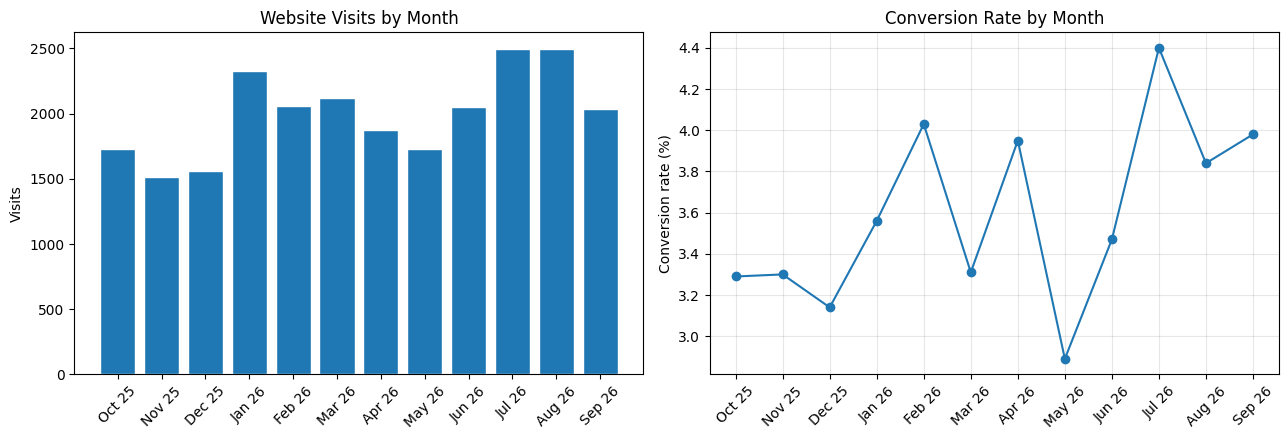

,visits,conversions,conversion_rate_pct
visit_month,,,
2025-10,1730,57,3.29
2025-11,1515,50,3.30
2025-12,1559,49,3.14
2026-01,2331,83,3.56
2026-02,2060,83,4.03
2026-03,2118,70,3.31
2026-04,1875,74,3.95
2026-05,1730,50,2.89
2026-06,2049,71,3.47


In [19]:
monthly = visits.groupby("visit_month").agg(visits=("visit_id", "count"), conversions=("converted", "sum"))
monthly["conversion_rate_pct"] = (monthly["conversions"] / monthly["visits"] * 100).round(2)
monthly_labels = monthly.index.strftime("%b %y")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(monthly_labels, monthly["visits"], edgecolor="white")
axes[0].set_title("Website Visits by Month")
axes[0].set_ylabel("Visits")
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(monthly_labels, monthly["conversion_rate_pct"], marker="o")
axes[1].set_title("Conversion Rate by Month")
axes[1].set_ylabel("Conversion rate (%)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

monthly

**Average visits per day of the week**

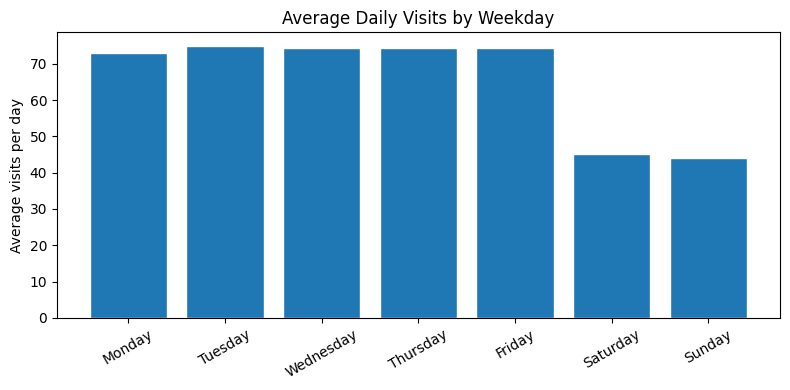

visit_date
Monday       73.0
Tuesday      74.9
Wednesday    74.3
Thursday     74.3
Friday       74.3
Saturday     45.1
Sunday       44.1
dtype: float64

In [20]:
daily_visits = visits.groupby("visit_date").size()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_avg = daily_visits.groupby(daily_visits.index.day_name()).mean().reindex(weekday_order).round(1)

plt.figure(figsize=(8, 4))
plt.bar(weekday_avg.index, weekday_avg.values, edgecolor="white")
plt.ylabel("Average visits per day")
plt.title("Average Daily Visits by Weekday")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

weekday_avg

**Observation:** the website received 24,000 visits in the year, with a bounce rate of
47.7%, an average of 2.7 pages per visit, an average session of about 2.0 minutes, and 874
conversions, a conversion rate of 3.64%. Traffic is seasonal: the busiest months are August
2026 (2,499 visits), July 2026 (2,498), and January 2026 (2,331), while November 2025 is the
quietest (1,515). The conversion rate moves less smoothly, from a low of 2.89% in May 2026
to a high of 4.40% in July 2026. Weekdays average about 74 visits per day compared with
about 45 on weekends, so weekday traffic is roughly 66% higher.

**Traffic channel performance**

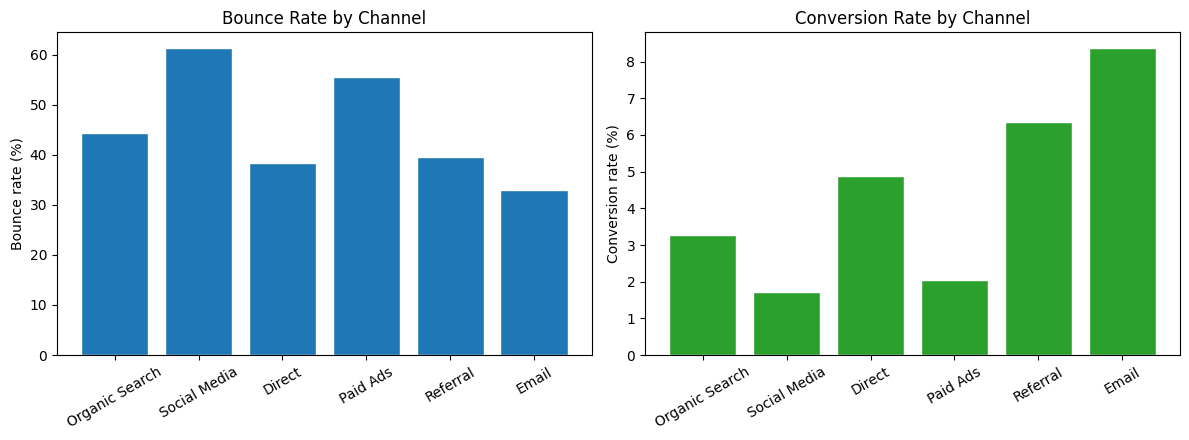

,visits,bounce_rate_pct,avg_pages,conversion_rate_pct,share_of_visits_pct
channel,,,,,
Organic Search,7674,44.27,2.79,3.28,31.98
Social Media,5734,61.37,2.23,1.71,23.89
Direct,3309,38.41,3.02,4.87,13.79
Paid Ads,3216,55.50,2.45,2.05,13.40
Referral,2157,39.45,2.93,6.35,8.99
Email,1910,33.04,3.12,8.38,7.96


In [21]:
channel_summary = visits.groupby("channel").agg(
    visits=("visit_id", "count"),
    bounce_rate_pct=("bounced", "mean"),
    avg_pages=("pages_viewed", "mean"),
    conversion_rate_pct=("converted", "mean"),
)
channel_summary["bounce_rate_pct"] *= 100
channel_summary["conversion_rate_pct"] *= 100
channel_summary["share_of_visits_pct"] = channel_summary["visits"] / len(visits) * 100
channel_summary = channel_summary.round(2).sort_values("visits", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(channel_summary.index, channel_summary["bounce_rate_pct"], edgecolor="white")
axes[0].set_title("Bounce Rate by Channel")
axes[0].set_ylabel("Bounce rate (%)")
axes[0].tick_params(axis="x", rotation=30)
axes[1].bar(channel_summary.index, channel_summary["conversion_rate_pct"], edgecolor="white", color="tab:green")
axes[1].set_title("Conversion Rate by Channel")
axes[1].set_ylabel("Conversion rate (%)")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

channel_summary

**Device, landing page, and region**

In [22]:
def traffic_summary(column):
    summary = visits.groupby(column).agg(
        visits=("visit_id", "count"), bounce_rate_pct=("bounced", "mean"), conversion_rate_pct=("converted", "mean"),
    )
    summary["bounce_rate_pct"] *= 100
    summary["conversion_rate_pct"] *= 100
    summary["share_of_visits_pct"] = summary["visits"] / len(visits) * 100
    return summary.round(2).sort_values("visits", ascending=False)


device_summary = traffic_summary("device")
landing_summary = traffic_summary("landing_page")
region_summary = traffic_summary("region")

print("By device")
print(device_summary)
print("\nBy landing page")
print(landing_summary)
print("\nBy region")
print(region_summary)

By device
         visits  bounce_rate_pct  conversion_rate_pct  share_of_visits_pct
device                                                                    
Mobile    15093            52.67                 2.68                62.89
Desktop    7168            38.28                 5.66                29.87
Tablet     1369            42.73                 3.65                 5.70
Unknown     370            47.57                 3.51                 1.54

By landing page
                  visits  bounce_rate_pct  conversion_rate_pct  \
landing_page                                                     
Internships         6209            51.78                 3.40   
Home                6169            46.67                 3.58   
Training            4041            43.90                 3.84   
IT Services         2846            45.33                 3.69   
Digital Services    2828            50.21                 3.50   
About               1020            46.27                 3.8

**What visitors convert into**

In [23]:
conversion_mix = visits.loc[visits["converted"] == 1, "conversion_type"].value_counts()
conversion_mix_pct = (conversion_mix / conversion_mix.sum() * 100).round(1)
pd.DataFrame({"conversions": conversion_mix, "share_pct": conversion_mix_pct})

,conversions,share_pct
conversion_type,,
Internship Application,294,33.6
Training Inquiry,247,28.3
IT Service Inquiry,177,20.3
Digital Service Inquiry,156,17.8


**Observation:** Organic Search brings the most traffic (32.0% of visits), but the channels
differ a lot in quality. Email is the best channel by far, with the lowest bounce rate
(33.0%) and the highest conversion rate (8.38%), even though it supplies only 8.0% of
visits, and Referral is second (6.35%). Social Media is the opposite: it is the
second-largest source (23.9% of visits) but has the highest bounce rate (61.4%) and the
lowest conversion rate (1.71%), about 4.9 times lower than Email. Paid Ads also underperform
(2.05%). Devices show a similar gap: mobile visitors are 62.9% of traffic but bounce more
(52.7% versus 38.3% on desktop) and convert at less than half the desktop rate (2.68% versus
5.66%). Landing pages matter much less: apart from the `Contact` page (4.96%, with only 3.7%
of visits), they all convert between 3.4% and 3.8%. Region barely matters either: 37.3% of
visits come from South India, and the known regions convert at 3.2% to 3.8%. Among visitors
who convert, Internship Application (33.6%) is the most common type, followed by Training
Inquiry (28.3%). These patterns come from the assumptions built into the simulation, so they
show how to read the analysis, not how Veda Technology's real visitors behave.

## 6. Internship Application Analysis

**Key figures for the year**

In [24]:
applications = clean_tables["internship_applications"].copy()
applications["is_selected"] = (applications["status"] == "Selected").astype(int)
applications["application_month"] = applications["application_date"].dt.to_period("M")

selected_count = applications["is_selected"].sum()
internship_kpis = pd.Series({
    "Total applications": len(applications),
    "Average assessment score": applications["assessment_score"].mean(),
    "Selection rate (% of applications)": applications["is_selected"].mean() * 100,
    "Enrollment rate (% of selected)": applications["enrolled"].sum() / selected_count * 100,
    "Enrolled interns": applications["enrolled"].sum(),
}).round(2)

internship_kpis.to_frame("value")

,value
Total applications,2600.00
Average assessment score,60.92
Selection rate (% of applications),36.08
Enrollment rate (% of selected),84.54
Enrolled interns,793.00


**Applications by month and by domain**

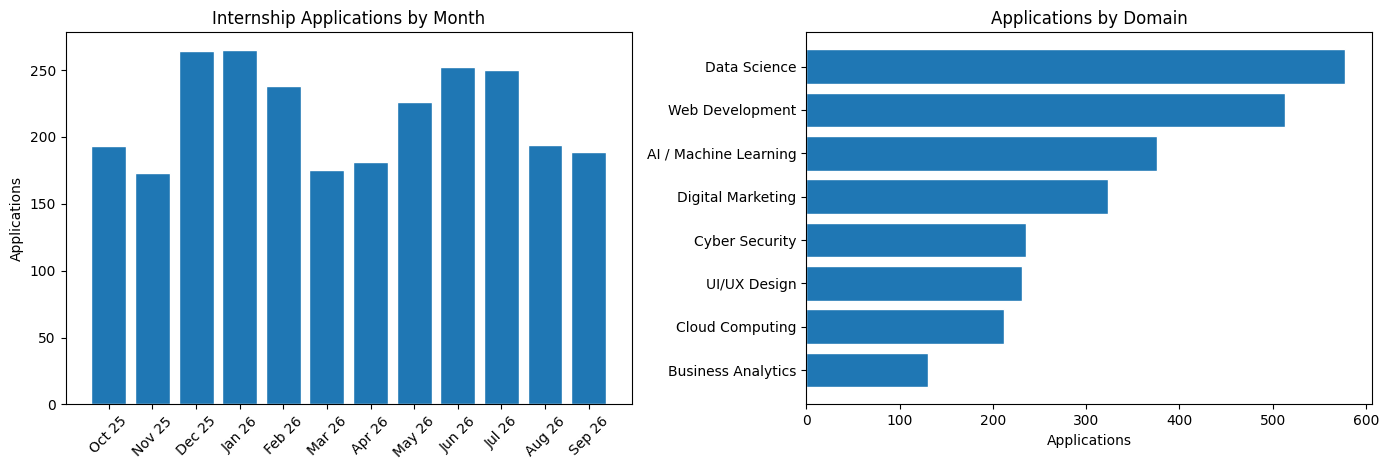

                   applications  selected  selection_rate_pct
application_month                                            
2025-10                     193        83                43.0
2025-11                     173        60                34.7
2025-12                     264        94                35.6
2026-01                     265        99                37.4
2026-02                     238        96                40.3
2026-03                     175        55                31.4
2026-04                     181        56                30.9
2026-05                     226        83                36.7
2026-06                     252        80                31.7
2026-07                     250        89                35.6
2026-08                     194        71                36.6
2026-09                     189        72                38.1

                       applications  avg_score  selection_rate_pct
domain                                                          

In [25]:
monthly_apps = applications.groupby("application_month").agg(
    applications=("application_id", "count"), selected=("is_selected", "sum"),
)
monthly_apps["selection_rate_pct"] = (monthly_apps["selected"] / monthly_apps["applications"] * 100).round(1)

domain_summary = applications.groupby("domain").agg(
    applications=("application_id", "count"), avg_score=("assessment_score", "mean"), selection_rate_pct=("is_selected", "mean"),
)
domain_summary["selection_rate_pct"] *= 100
domain_summary = domain_summary.round(2).sort_values("applications", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(monthly_apps.index.strftime("%b %y"), monthly_apps["applications"], edgecolor="white")
axes[0].set_title("Internship Applications by Month")
axes[0].set_ylabel("Applications")
axes[0].tick_params(axis="x", rotation=45)
axes[1].barh(domain_summary.index[::-1], domain_summary["applications"][::-1], edgecolor="white")
axes[1].set_title("Applications by Domain")
axes[1].set_xlabel("Applications")
plt.tight_layout()
plt.show()

print(monthly_apps)
print()
print(domain_summary)

**Who gets selected? College tier, education level, and program length**

In [26]:
def selection_summary(column):
    summary = applications.groupby(column).agg(
        applications=("application_id", "count"), avg_score=("assessment_score", "mean"), selection_rate_pct=("is_selected", "mean"),
    )
    summary["selection_rate_pct"] *= 100
    return summary.round(2)


tier_summary = selection_summary("college_tier")
education_summary = selection_summary("education_level")
duration_summary = selection_summary("program_duration")

print(tier_summary)
print()
print(education_summary)
print()
print(duration_summary)

              applications  avg_score  selection_rate_pct
college_tier                                             
Tier 1                 313      67.09               50.48
Tier 2                 947      62.03               37.91
Tier 3                1291      58.56               31.14
Unknown                 49      62.48               38.78

                 applications  avg_score  selection_rate_pct
education_level                                             
Diploma                   270      58.87               34.81
Postgraduate              485      64.31               41.03
Undergraduate            1845      60.33               34.96

                  applications  avg_score  selection_rate_pct
program_duration                                             
30-Day                    1580      60.93               36.33
45-Day                    1020      60.91               35.69


**Assessment score and the application outcome**

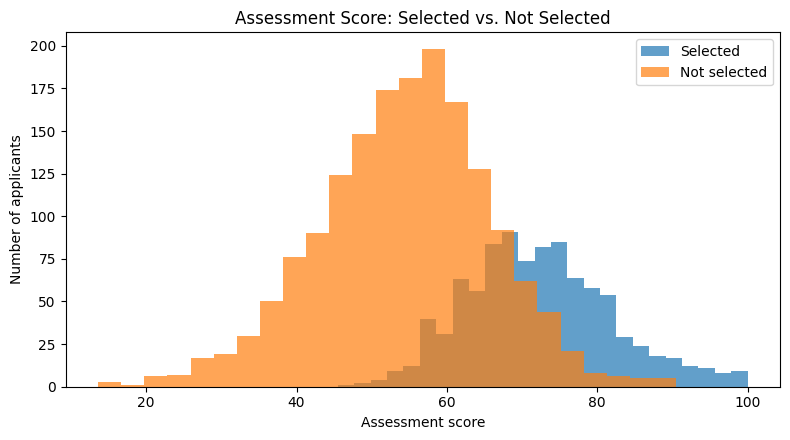

,count,mean,median
status,,,
Rejected,1201,51.8,52.2
Selected,938,72.3,71.8
Waitlisted,238,62.5,61.5
Withdrawn,223,60.6,61.0


In [27]:
score_by_status = applications.groupby("status")["assessment_score"].agg(["count", "mean", "median"]).round(1)

plt.figure(figsize=(8, 4.5))
plt.hist(applications.loc[applications["is_selected"] == 1, "assessment_score"], bins=25, alpha=0.7, label="Selected")
plt.hist(applications.loc[applications["is_selected"] == 0, "assessment_score"], bins=25, alpha=0.7, label="Not selected")
plt.xlabel("Assessment score")
plt.ylabel("Number of applicants")
plt.title("Assessment Score: Selected vs. Not Selected")
plt.legend()
plt.tight_layout()
plt.show()

score_by_status

**Observation:** Veda Technology received 2,600 internship applications, with an average
assessment score of 60.9, and selected 36.1% of applicants. Applications peak in January
2026 (265) and December 2025 (264) and are lowest in November 2025 (173). Data Science is
the largest domain (578 applications, 22.2%), followed by Web Development, while Business
Analytics is the smallest (131). Selection rates range from 30.9% (Cyber Security) to 43.7%
(UI/UX Design), but the domains with fewer applicants have noisier rates, so those gaps
should not be over-read. The clearest pattern is the college tier: Tier 1 applicants are
selected 50.5% of the time versus 31.1% for Tier 3, with average scores of 67.1 versus 58.6,
yet 50% of all applications come from Tier 3. Postgraduate applicants also do better (41.0%
selected) than undergraduates (35.0%) and diploma students (34.8%), while program length
makes no difference (36.3% versus 35.7%). Selection follows the assessment score closely:
selected applicants average 72.3 versus 51.8 for rejected ones, while withdrawn applicants
(60.6) look like the typical applicant.

**Application sources: which channels bring the best applicants?**

In [28]:
source_summary = applications.groupby("source").agg(
    applications=("application_id", "count"), avg_score=("assessment_score", "mean"),
    selected=("is_selected", "sum"), enrolled=("enrolled", "sum"),
)
source_summary["selection_rate_pct"] = source_summary["selected"] / source_summary["applications"] * 100
source_summary["enrollment_rate_pct"] = source_summary["enrolled"] / source_summary["selected"] * 100
source_summary = source_summary.round(2).sort_values("applications", ascending=False)
source_summary

,applications,avg_score,selected,enrolled,selection_rate_pct,enrollment_rate_pct
source,,,,,,
Website,657,61.11,235,191,35.77,81.28
Campus Outreach,556,60.67,192,177,34.53,92.19
LinkedIn,554,60.47,203,162,36.64,79.80
Instagram,359,60.92,140,114,39.00,81.43
Referral,301,60.86,112,106,37.21,94.64
Email Campaign,173,62.61,56,43,32.37,76.79


**The same question in SQL**

SQL is part of the project toolkit, so the selection rate by domain is calculated again with
a SQL query on an in-memory SQLite database and compared with the pandas result.

In [29]:
conn = sqlite3.connect(":memory:")
applications[["application_id", "application_date", "domain", "status", "assessment_score"]].to_sql(
    "internship_applications", conn, index=False
)

query = '''
SELECT domain,
       COUNT(*) AS applications,
       ROUND(100.0 * SUM(CASE WHEN status = 'Selected' THEN 1 ELSE 0 END) / COUNT(*), 2) AS selection_rate_pct
FROM internship_applications
GROUP BY domain
ORDER BY applications DESC;
'''
sql_result = pd.read_sql_query(query, conn)
conn.close()

check = sql_result.merge(domain_summary.reset_index(), on="domain", suffixes=("_sql", "_pandas"))
print("SQL matches pandas:",
      (check["applications_sql"] == check["applications_pandas"]).all()
      and np.allclose(check["selection_rate_pct_sql"], check["selection_rate_pct_pandas"], atol=0.01))
sql_result

SQL matches pandas: True


,domain,applications,selection_rate_pct
0,Data Science,578,35.99
1,Web Development,513,36.65
2,AI / Machine Learning,376,34.57
3,Digital Marketing,323,35.91
4,Cyber Security,236,30.93
5,UI/UX Design,231,43.72
6,Cloud Computing,212,34.91
7,Business Analytics,131,36.64


**Observation:** Website is the largest source (657 applications, 25.3%), and the sources
send applicants of similar quality, with average scores between 60.5 and 62.6 and selection
rates between 32.4% and 39.0%. The real difference is what happens after selection: Referral
(94.6%) and Campus Outreach (92.2%) applicants almost always enroll, while Email Campaign
(76.8%) and LinkedIn (79.8%) have the lowest enrollment rates. Together, Campus Outreach and
Referral supplied 33% of the applications but 36% of the enrolled interns. The SQL query
returns exactly the same domain figures as pandas. Overall, 793 interns enrolled, an
enrollment rate of 84.5% of selected applicants.

## Outcome

This notebook started the Veda Technology Business & Service Analytics project. It created a
simulated business dataset of seven tables (website visits, internship applications,
training enrollments, IT and digital service inquiries, service requests, and marketing
campaigns) covering one year, made it deliberately messy, and built one specification-driven
cleaning pipeline that turned 34,269 raw rows into 34,060 clean ones by removing 209
duplicates, standardizing 5,041 labels, handling 195 impossible numbers, and filling 940
gaps. Validation checks and a comparison with the original tables confirmed that the cleaned
data was correct. The website analysis found 24,000 visits, a 47.7% bounce rate, and a 3.64%
conversion rate, with Email and Referral converting best, Social Media and Paid Ads
converting worst, mobile visitors converting at less than half the desktop rate, and traffic
peaking in the summer and in January. The internship analysis found a 36.1% selection rate
driven by the assessment score and the college tier, and that Referral and Campus Outreach
applicants enroll most often. Because the data is simulated, these findings reflect the
assumptions built into it and practice the analysis workflow instead of describing the real
company. The cleaned tables are saved in `datasets/veda_business/cleaned/` for the next
three days of the project.